# Module 7 — Production & LLMOps, runnable

**The problem.** The pilot worked on one box. Production breaks on the things web apps don't have: capacity is **tokens per second**, not requests per second; long context is a **memory** problem, not a compute one; the autoscaler must watch the **queue**, not the CPU; and a default load-balancer timeout **cuts off** a long generation. This notebook makes each of those concrete and measurable.

Deterministic capacity math and sims where the mechanism is the point; **one real measurement** (streaming time-to-first-token vs total) for the timeout lesson. The capacity/KV numbers are **illustrative constants** (named, change them) — the *scaling* is the lesson, not the exact GB. Needs Ollama (`qwen2.5:7b`) only for the streaming cell.


## 0. Setup


In [1]:
import sys, pathlib, importlib, math, time, json as _json
import requests
here = pathlib.Path.cwd()
for p in (here, here/"notebooks", here.parent):
    if (p/"arch_kit.py").exists(): sys.path.insert(0, str(p)); break
import arch_kit; importlib.reload(arch_kit)
print("ready —", arch_kit.CHAT_MODEL, "via", arch_kit.OLLAMA)


ready — qwen2.5:7b via http://127.0.0.1:11434


## 1. Size on tokens/sec, not QPS

A web request is ~constant work; an LLM request is **its output length**. Two services at the *same QPS* can need wildly different capacity, because generation (decode) time tracks output tokens. So you size on **tokens/sec**, not requests/sec.


In [2]:
BOX_TOKENS_PER_SEC = 2000   # one GPU box's sustained decode throughput (illustrative; measure yours)

def boxes_needed(rps, avg_output_tokens):
    return math.ceil(rps * avg_output_tokens / BOX_TOKENS_PER_SEC)

for label, rps, out in [("chat (short replies)", 100, 50),
                        ("drafting (long replies)", 100, 500),
                        ("report gen (very long out)", 100, 1500)]:
    tps = rps*out
    print(f"{label:24} QPS={rps:3}  out~{out:4} tok  -> {tps:>7,} tok/s  -> {boxes_needed(rps,out):2} box(es)")
print("\nsame QPS (100), 3 vs 25 vs 75 boxes -- QPS tells you almost nothing; tokens/sec is the unit.")


chat (short replies)     QPS=100  out~  50 tok  ->   5,000 tok/s  ->  3 box(es)
drafting (long replies)  QPS=100  out~ 500 tok  ->  50,000 tok/s  -> 25 box(es)
report gen (very long out) QPS=100  out~1500 tok  -> 150,000 tok/s  -> 75 box(es)

same QPS (100), 3 vs 25 vs 75 boxes -- QPS tells you almost nothing; tokens/sec is the unit.


**Read it.** Identical QPS, a 3-to-75-box spread (~25×), because the output length is the real workload. If you capacity-plan on requests/sec you under-provision the long-output service by that factor. Size on **tokens/sec = QPS × output-tokens** (plus the input/prefill cost — cheaper per token because it runs in parallel, but not free). And measure the box's real **aggregate** throughput at your target concurrency and context, **not** a single stream: under continuous batching aggregate tok/s *rises* with batch size up to a memory/bandwidth saturation point while *per-request* speed falls — so a single-stream benchmark will over-provision you by a large factor.


## 2. Long context is a memory problem — the KV cache, not the FLOPs

Each token in the context holds a **KV-cache** entry on the GPU, for every concurrent request. KV memory grows **linearly with context length × concurrency** — and that, not compute, is what OOMs a box. Doubling the context or the concurrency doubles the memory.


In [3]:
# REAL Qwen2.5-7B dims (28 layers, 4 KV heads via GQA, head_dim 128) -> 56 KB/token in fp16. Llama-3-8B is ~128 KB.
LAYERS, KV_HEADS, HEAD_DIM, DTYPE_BYTES = 28, 4, 128, 2        # fp16
KV_BYTES_PER_TOKEN = 2 * LAYERS * KV_HEADS * HEAD_DIM * DTYPE_BYTES   # k and v
GPU_GB, WEIGHTS_GB = 24, 15        # a 7B in fp16 is ~15 GB of weights -> the KV must fit in what's LEFT
KV_BUDGET_GB = GPU_GB - WEIGHTS_GB

def kv_gb(ctx_tokens, concurrency):
    return KV_BYTES_PER_TOKEN * ctx_tokens * concurrency / 1e9

print(f"KV per token = {KV_BYTES_PER_TOKEN/1024:.0f} KB  | GPU {GPU_GB} GB - weights {WEIGHTS_GB} GB = {KV_BUDGET_GB} GB for KV\n")
for ctx, conc in [(4096,16),(8192,16),(8192,32),(16384,32)]:
    gb = kv_gb(ctx, conc)
    print(f"ctx={ctx:5}  concurrency={conc:2}  -> KV {gb:5.1f} GB  {'OK' if gb < KV_BUDGET_GB else 'OOM -> trim/summarise or shard'}")
print("\nlinear in ctx x concurrency: double either and the memory doubles. And KV competes with the ~15 GB of")
print("weights, so the real headroom is small. Agent memory / long multi-turn histories are the usual culprit")
print("-> trim, summarise, or page the context; at long context this box is MEMORY-bound, not compute-bound.")


KV per token = 56 KB  | GPU 24 GB - weights 15 GB = 9 GB for KV

ctx= 4096  concurrency=16  -> KV   3.8 GB  OK
ctx= 8192  concurrency=16  -> KV   7.5 GB  OK
ctx= 8192  concurrency=32  -> KV  15.0 GB  OOM -> trim/summarise or shard
ctx=16384  concurrency=32  -> KV  30.1 GB  OOM -> trim/summarise or shard

linear in ctx x concurrency: double either and the memory doubles. And KV competes with the ~15 GB of
weights, so the real headroom is small. Agent memory / long multi-turn histories are the usual culprit
-> trim, summarise, or page the context; at long context this box is MEMORY-bound, not compute-bound.


**Read it.** KV competes with the model's **weights**: the ~15 GB of a 7B in fp16 leaves only ~9 GB for KV on a 24 GB card, so even 8k context × 32 concurrent requests (15 GB of KV) overruns it — and 16k × 32 (30 GB) is hopeless. At long context this box is **memory-bound**: the lever isn't a faster chip, it's **shrinking the context** (trim old turns, summarise agent memory, page/retrieve) or sharding. (Prefill at long context is compute-heavy too; the point is that *memory* is the binding limit here.) Long multi-turn and agent histories are the usual cause — which is why M2b's 'retrieve, don't stuff' is a *capacity* decision, not only a quality one.


## 3. Stateless workers + externalised session state — so you can scale horizontally

Horizontal scaling needs any worker to handle any request. If session state lives *in the worker* (sticky sessions), losing or scaling a worker loses the conversation. Put state in a **shared store** (Redis/DB); workers stay stateless and disposable.


In [4]:
# STATELESS: session state in a shared store -> any worker serves any turn; a worker can die
SHARED = {}
def worker_stateless(wid, session, turn):
    SHARED.setdefault(session, []).append(turn)
    return list(SHARED[session])

# STICKY: state lives in the worker -> that worker must handle every turn of the session
LOCAL = {0: {}, 1: {}, 2: {}}
def worker_sticky(wid, session, turn):
    LOCAL[wid].setdefault(session, []).append(turn)
    return list(LOCAL[wid][session])

# a 3-turn conversation, each turn routed to a DIFFERENT worker (round-robin), then a worker dies
print("STATELESS (shared store):")
for i, turn in enumerate(["hi", "my order is late", "where is it?"]):
    hist = worker_stateless(i % 3, "sess-A", turn)
    print(f"  turn {i} -> worker {i%3}  history={hist}")
print("  -> full history preserved across workers; kill any worker and the next still has it\n")

print("STICKY (worker-local):")
for i, turn in enumerate(["hi", "my order is late"]):
    worker_sticky(0, "sess-B", turn)
print(f"  worker 0 holds: {LOCAL[0]['sess-B']}")
print(f"  worker 0 unavailable; next turn rerouted to worker 1 -> history={worker_sticky(1, 'sess-B', 'where is it?')}")
print("  -> conversation LOST: worker 1 never had sess-B")


STATELESS (shared store):
  turn 0 -> worker 0  history=['hi']
  turn 1 -> worker 1  history=['hi', 'my order is late']
  turn 2 -> worker 2  history=['hi', 'my order is late', 'where is it?']
  -> full history preserved across workers; kill any worker and the next still has it

STICKY (worker-local):
  worker 0 holds: ['hi', 'my order is late']
  worker 0 unavailable; next turn rerouted to worker 1 -> history=['where is it?']
  -> conversation LOST: worker 1 never had sess-B


**Read it.** The stateless worker rebuilds the whole conversation from the shared store on every turn, so turns can land on any worker and a dying worker costs nothing. The sticky worker owns the session, so losing it (a crash, a scale-down, a rebalance) **drops the conversation**. The real cost of stateless is **re-prefill**: the shared store holds the conversation *text*, not its KV cache, so a reroute re-processes the whole history — which is why production servers (vLLM/SGLang) offer **prefix-cache-aware routing** as the middle ground. Default to stateless + externalised state; reach for affinity only when you've measured the re-prefill cost actually hurts.


## 4. Streaming-aware timeouts — a default LB timeout cuts off a long generation

A long generation can run longer than a default load-balancer/API-gateway timeout (often 30–60s, sometimes 10s). **Streaming** sends the first token early — a small fraction of the total — so the connection is alive and the user sees progress, while the non-streaming call just hangs silently until the timeout kills it. We measure both (after a warm-up, so the first-token time is prefill, not a cold model load).


In [5]:
DEFAULT_LB_TIMEOUT = 10.0   # a typical default that was never tuned for LLMs

def stream_timing(prompt, num_predict):
    t0 = time.perf_counter(); ttft = None
    r = requests.post(arch_kit.OLLAMA + "/api/chat",
                      json={"model": arch_kit.CHAT_MODEL, "messages":[{"role":"user","content":prompt}],
                            "stream": True, "options":{"temperature":0.0,"num_predict":num_predict}},
                      stream=True, timeout=120)
    for line in r.iter_lines():
        if not line: continue
        d = _json.loads(line)
        if ttft is None and d.get("message",{}).get("content"): ttft = time.perf_counter()-t0
        if d.get("done"): break
    return ttft, time.perf_counter()-t0

_ = arch_kit.chat("warm up", num_predict=1)   # load the model first, so TTFT reflects prefill, not a cold start
PROMPT = "Write a detailed paragraph about warehouse logistics operations."
ttft, total = stream_timing(PROMPT, num_predict=200)
print(f"STREAMING : first token {ttft:.2f}s, total {total:.2f}s  (LB timeout set to {DEFAULT_LB_TIMEOUT}s)")

# actually MEASURE the non-streaming call against the same timeout -> observe the cut-off (not arithmetic)
import requests as _rq
t0 = time.perf_counter()
try:
    _rq.post(arch_kit.OLLAMA + "/api/chat",
             json={"model": arch_kit.CHAT_MODEL, "messages":[{"role":"user","content":PROMPT}],
                   "stream": False, "options":{"temperature":0.0,"num_predict":200}},
             timeout=(5, DEFAULT_LB_TIMEOUT))
    print(f"NON-STREAM: returned in {time.perf_counter()-t0:.2f}s (under the timeout this run)")
except _rq.exceptions.ReadTimeout:
    print(f"NON-STREAM: *** CUT OFF at {DEFAULT_LB_TIMEOUT}s (ReadTimeout) *** -- the whole generation is lost")
print(f"-> streaming delivered a first token at {ttft:.2f}s; the non-streaming call held a silent connection.")


STREAMING : first token 0.24s, total 16.50s  (LB timeout set to 10.0s)


NON-STREAM: *** CUT OFF at 10.0s (ReadTimeout) *** -- the whole generation is lost
-> streaming delivered a first token at 0.24s; the non-streaming call held a silent connection.


**Read it.** Time-to-first-token is a small fraction of the total: the user sees output almost immediately while the full generation runs for many seconds. A non-streaming request holds a silent connection for the whole total, and a default timeout tuned for web APIs severs it mid-generation — a failure you *cause* by not tuning the timeout. Stream the response (first token early keeps the connection alive), and set the timeout against the P99 **total**, not a web default. One caveat: streaming beats an **idle** timeout (each token resets the clock — ALB, nginx `proxy_read_timeout`), but a **total-duration** cap (API Gateway's 29s, many serverless limits) still cuts you off, so the P99-total setting is mandatory either way. (Exact seconds vary by run/hardware — here the timeout is set low to show the effect at 200 tokens; ALB/nginx default to ~60s; the gap between TTFT and total is the point.)


## 5. Autoscale on the queue, not the CPU

Inference is GPU-bound: the CPU sits near-idle while the GPU is saturated and the request **queue** grows. A CPU-threshold autoscaler never fires and you silently under-provision. Scale on **queue depth / P95 queue-wait / token-throughput saturation** instead.


In [6]:
LOAD = [20, 40, 80, 160, 160, 80]   # incoming rps over six intervals (a burst)
CAP_PER_BOX = 50                    # rps one box can clear

def simulate(signal):
    boxes, queue, log = 1, 0, []
    for rps in LOAD:
        cpu = 35                                   # GPU-bound: CPU stays ~35% no matter the load
        queue = max(0, queue + rps - boxes*CAP_PER_BOX)
        if signal == "cpu"   and cpu   > 70: boxes += 1     # never fires
        if signal == "queue" and queue > 50: boxes += 1     # fires on backlog
        log.append((rps, cpu, boxes, queue))
    return log

print("signal=CPU% (threshold 70):")
for rps,cpu,b,q in simulate("cpu"):   print(f"  rps={rps:3} cpu={cpu}% boxes={b} queue={q}")
print("signal=QUEUE depth (threshold 50):")
for rps,cpu,b,q in simulate("queue"): print(f"  rps={rps:3} cpu={cpu}% boxes={b} queue={q}")
print("\nCPU stays 35% so the CPU autoscaler never scales and the queue runs away; the queue autoscaler adds boxes.")


signal=CPU% (threshold 70):
  rps= 20 cpu=35% boxes=1 queue=0
  rps= 40 cpu=35% boxes=1 queue=0
  rps= 80 cpu=35% boxes=1 queue=30
  rps=160 cpu=35% boxes=1 queue=140
  rps=160 cpu=35% boxes=1 queue=250
  rps= 80 cpu=35% boxes=1 queue=280
signal=QUEUE depth (threshold 50):
  rps= 20 cpu=35% boxes=1 queue=0
  rps= 40 cpu=35% boxes=1 queue=0
  rps= 80 cpu=35% boxes=1 queue=30
  rps=160 cpu=35% boxes=2 queue=140
  rps=160 cpu=35% boxes=3 queue=200
  rps= 80 cpu=35% boxes=4 queue=130

CPU stays 35% so the CPU autoscaler never scales and the queue runs away; the queue autoscaler adds boxes.


**Read it.** We *assume* CPU stays flat (~35%, typical of a GPU-saturated inference server). With a CPU trigger the box count then never moves and the queue climbs unbounded (users see timeouts); the queue-depth trigger adds boxes as the backlog builds and keeps it bounded. The lesson isn't the exact numbers — it's that the signal must match where the work actually is: queue depth, P95 queue wait, token-throughput saturation, or GPU-memory pressure — **not** CPU%. (The sim also omits scale-in and provisioning lag — a real GPU box takes minutes to pull a model, so you pre-warm and keep headroom.)


## 6. Multi-region posture — chosen by the driver, not by default

Going multi-region is a deliberate trade, and the *driver* picks the shape: latency, cost, or compliance. A decision function from the driver (and it must fail closed on an unknown one).


In [7]:
KNOWN_DRIVERS = {"latency","cost","residency"}
def region_posture(driver):
    if driver not in KNOWN_DRIVERS: return "needs-review (unknown driver)"
    return {"latency":   "active-active — serve every region from its nearest replica",
            "cost":      "active-passive — one live region + a warm standby, fail over on outage",
            "residency": "region-locked — data must not leave the jurisdiction; no cross-region replication"}[driver]
for d in ["latency","cost","residency","vibes"]:
    print(f"{d:10} -> {region_posture(d)}")


latency    -> active-active — serve every region from its nearest replica
cost       -> active-passive — one live region + a warm standby, fail over on outage
residency  -> region-locked — data must not leave the jurisdiction; no cross-region replication
vibes      -> needs-review (unknown driver)


**Read it.** Latency → active-active (users hit the nearest region); cost → active-passive (pay for one region plus a cheap standby, accept failover time); residency → region-locked (compliance forbids the data crossing a border, so you *can't* replicate even if you wanted the latency). The driver decides; 'multi-region because it sounds robust' is how you overpay or break residency. An unknown driver fails to needs-review, never to a silent default.


### Production topology


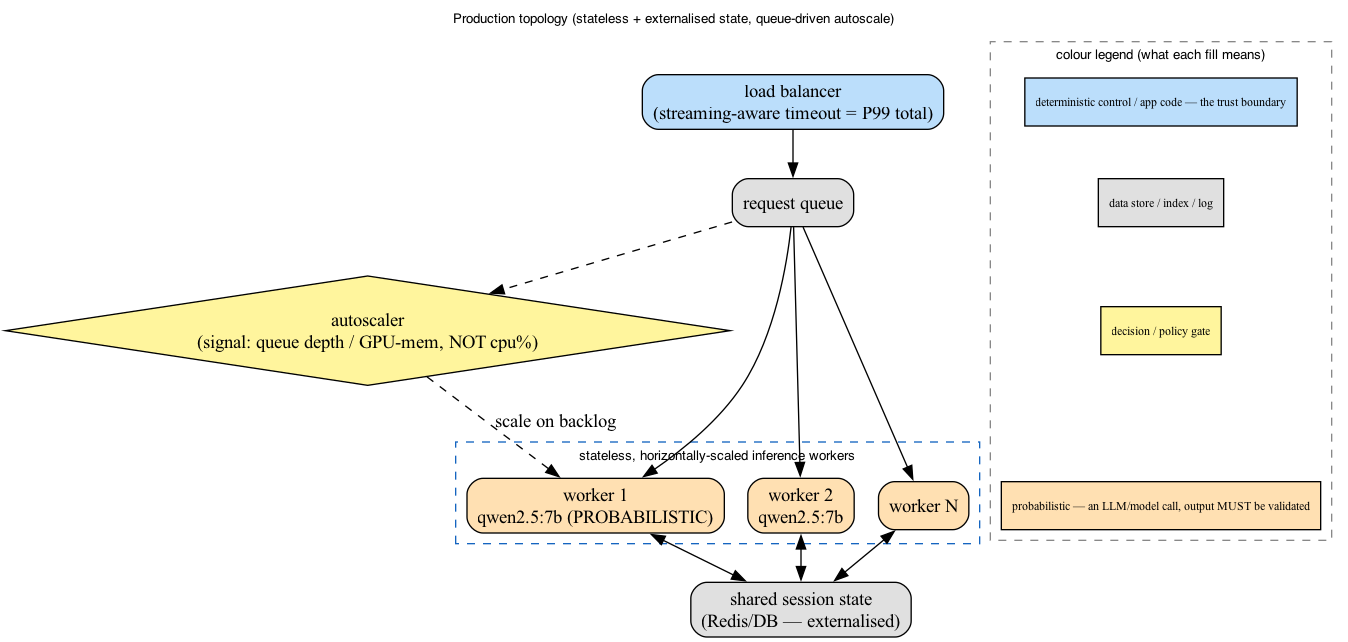

In [8]:
from graphviz import Digraph
from IPython.display import Image, display
from arch_kit import dnode, diagram_legend
g = Digraph(); g.attr(rankdir="TB", fontname="Helvetica", fontsize="10", labelloc="t",
                      label="Production topology (stateless + externalised state, queue-driven autoscale)")
dnode(g,"lb","load balancer\n(streaming-aware timeout = P99 total)","control")
dnode(g,"q","request queue","data")
dnode(g,"as","autoscaler\n(signal: queue depth / GPU-mem, NOT cpu%)","gate")
with g.subgraph(name="cluster_w") as c:
    c.attr(label="stateless, horizontally-scaled inference workers", style="dashed", color="#1565c0", fontsize="10")
    dnode(c,"w1","worker 1\nqwen2.5:7b (PROBABILISTIC)","model")
    dnode(c,"w2","worker 2\nqwen2.5:7b","model")
    dnode(c,"wn","worker N","model")
dnode(g,"state","shared session state\n(Redis/DB — externalised)","data")
g.edge("lb","q"); g.edge("q","w1"); g.edge("q","w2"); g.edge("q","wn")
g.edge("as","w1",label="scale on backlog", style="dashed"); g.edge("q","as", style="dashed")
for w in ("w1","w2","wn"): g.edge(w,"state",dir="both")
diagram_legend(g, ["control","data","gate","model"])
try: display(Image(g.pipe(format="png")))
except Exception as e: print("diagram render skipped (needs the graphviz 'dot' binary):", e)


## 7. Meaningful tests

Checks that the models here behave as narrated (the sims and the capacity math, not production itself); the streaming TTFT is reported, and we assert it's a small fraction of the total.


In [9]:
def run_checks():
    checks=[]
    def check(n,c,w): checks.append((n,"PASS" if c else "FAIL",w))

    # capacity: same QPS, more output tokens -> strictly more boxes (QPS is the wrong unit)
    check("same QPS but longer output needs more boxes (size on tokens, not QPS)",
          boxes_needed(100,500) > boxes_needed(100,50),
          "capacity is tokens/sec = QPS x output; planning on QPS under-provisions long-output services")
    # KV memory is linear in ctx x concurrency, and the big case OOMs the KV BUDGET (after weights)
    check("KV memory is linear in ctx x concurrency and OOMs the KV budget (GPU - weights)",
          abs(kv_gb(16384,32) - 2*kv_gb(8192,32)) < 1e-9 and kv_gb(16384,32) > KV_BUDGET_GB and kv_gb(4096,16) < KV_BUDGET_GB,
          "long context is a memory problem; KV competes with the weights, and the fix is a smaller context")
    # stateless survives a worker loss; sticky loses the conversation
    SHARED.clear(); LOCAL[0].clear(); LOCAL[1].clear()
    for i,t in enumerate(["a","b","c"]): worker_stateless(i%3,"S",t)
    stateless_ok = SHARED["S"] == ["a","b","c"]
    worker_sticky(0,"T","a"); lost = worker_sticky(1,"T","b")   # turn 2 on a different worker
    check("stateless preserves history across workers; sticky loses it on reroute",
          stateless_ok and lost == ["b"],
          "externalised state lets any worker serve any turn; sticky drops the session on worker loss")
    # streaming: first token is a small fraction of the total (robust across hardware, unlike an absolute bar)
    check(f"streaming TTFT is a small fraction of total (ttft {ttft:.2f}s vs total {total:.2f}s)",
          ttft < total * 0.25,
          "streaming delivers the first token early; the client sees progress long before the full generation")
    # autoscale: the CPU signal leaves a bigger backlog than the queue signal
    check("queue-signal autoscaler ends with a smaller backlog than the CPU-signal one",
          simulate("queue")[-1][3] < simulate("cpu")[-1][3],
          "CPU is flat on a GPU-bound service; scale on the queue or you never scale")
    # region posture: driver-derived, fails closed on unknown
    check("region posture is driver-derived and fails closed on an unknown driver",
          region_posture("residency").startswith("region-locked") and region_posture("x").startswith("needs-review"),
          "multi-region is a deliberate trade chosen by the driver, not a default")

    import pandas as pd
    print(pd.DataFrame(checks, columns=["check","result","why it matters"]).to_string(index=False))
    assert all(r=="PASS" for _,r,_ in checks), "a production guarantee broke"
    print("\nall", len(checks), "meaningful checks passed")
run_checks()


                                                                          check result                                                                                     why it matters
          same QPS but longer output needs more boxes (size on tokens, not QPS)   PASS       capacity is tokens/sec = QPS x output; planning on QPS under-provisions long-output services
KV memory is linear in ctx x concurrency and OOMs the KV budget (GPU - weights)   PASS   long context is a memory problem; KV competes with the weights, and the fix is a smaller context
         stateless preserves history across workers; sticky loses it on reroute   PASS         externalised state lets any worker serve any turn; sticky drops the session on worker loss
       streaming TTFT is a small fraction of total (ttft 0.24s vs total 16.50s)   PASS streaming delivers the first token early; the client sees progress long before the full generation
    queue-signal autoscaler ends with a smaller backlog than the CPU-s

## Check your understanding

**Q1.** Two services both run at 100 QPS. Why might one need 3 boxes and the other 25?
<details><summary>answer</summary>Because an LLM request's work is its *output length*, not the request itself. Generation (decode) time scales with tokens produced, so a service with 50-token replies and one with 500-token replies differ ~10× in tokens/sec at the same QPS — and capacity is tokens/sec = QPS × output-tokens. Size on tokens/sec (measured under real concurrency and context length), never on QPS.</details>

**Q2.** A box has plenty of spare compute but keeps OOMing under load. What's the likely cause and the fix?
<details><summary>answer</summary>The **KV cache**. Every context token holds a KV entry on the GPU for every concurrent request, so memory grows linearly with context-length × concurrency and overruns the GPU long before compute does. The fix is to shrink the context — trim old turns, summarise agent memory, page or retrieve instead of stuffing — or shard; a faster chip doesn't help a memory limit.</details>

**Q3.** Why default to stateless workers with externalised session state instead of sticky sessions?
<details><summary>answer</summary>Horizontal scaling and resilience need *any* worker to handle *any* request. With sticky sessions the conversation lives in one worker, so a crash, scale-down, or rebalance drops it. Stateless workers rebuild the session from a shared store (Redis/DB) each turn, so workers are disposable and you can scale freely. Reserve sticky routing for state you've measured is too big to fetch.</details>

**Q4.** Your CPU-based autoscaler never triggers, yet users report timeouts under load. Why, and what should it watch?
<details><summary>answer</summary>Inference is GPU-bound, so the CPU sits near-idle while the GPU is saturated and the request **queue** backs up — the CPU threshold never crosses, so no scaling happens and the backlog becomes timeouts. Autoscale on the signal that reflects the real bottleneck: queue depth, P95 queue-wait, token-throughput saturation, or GPU-memory pressure — not CPU%.</details>
